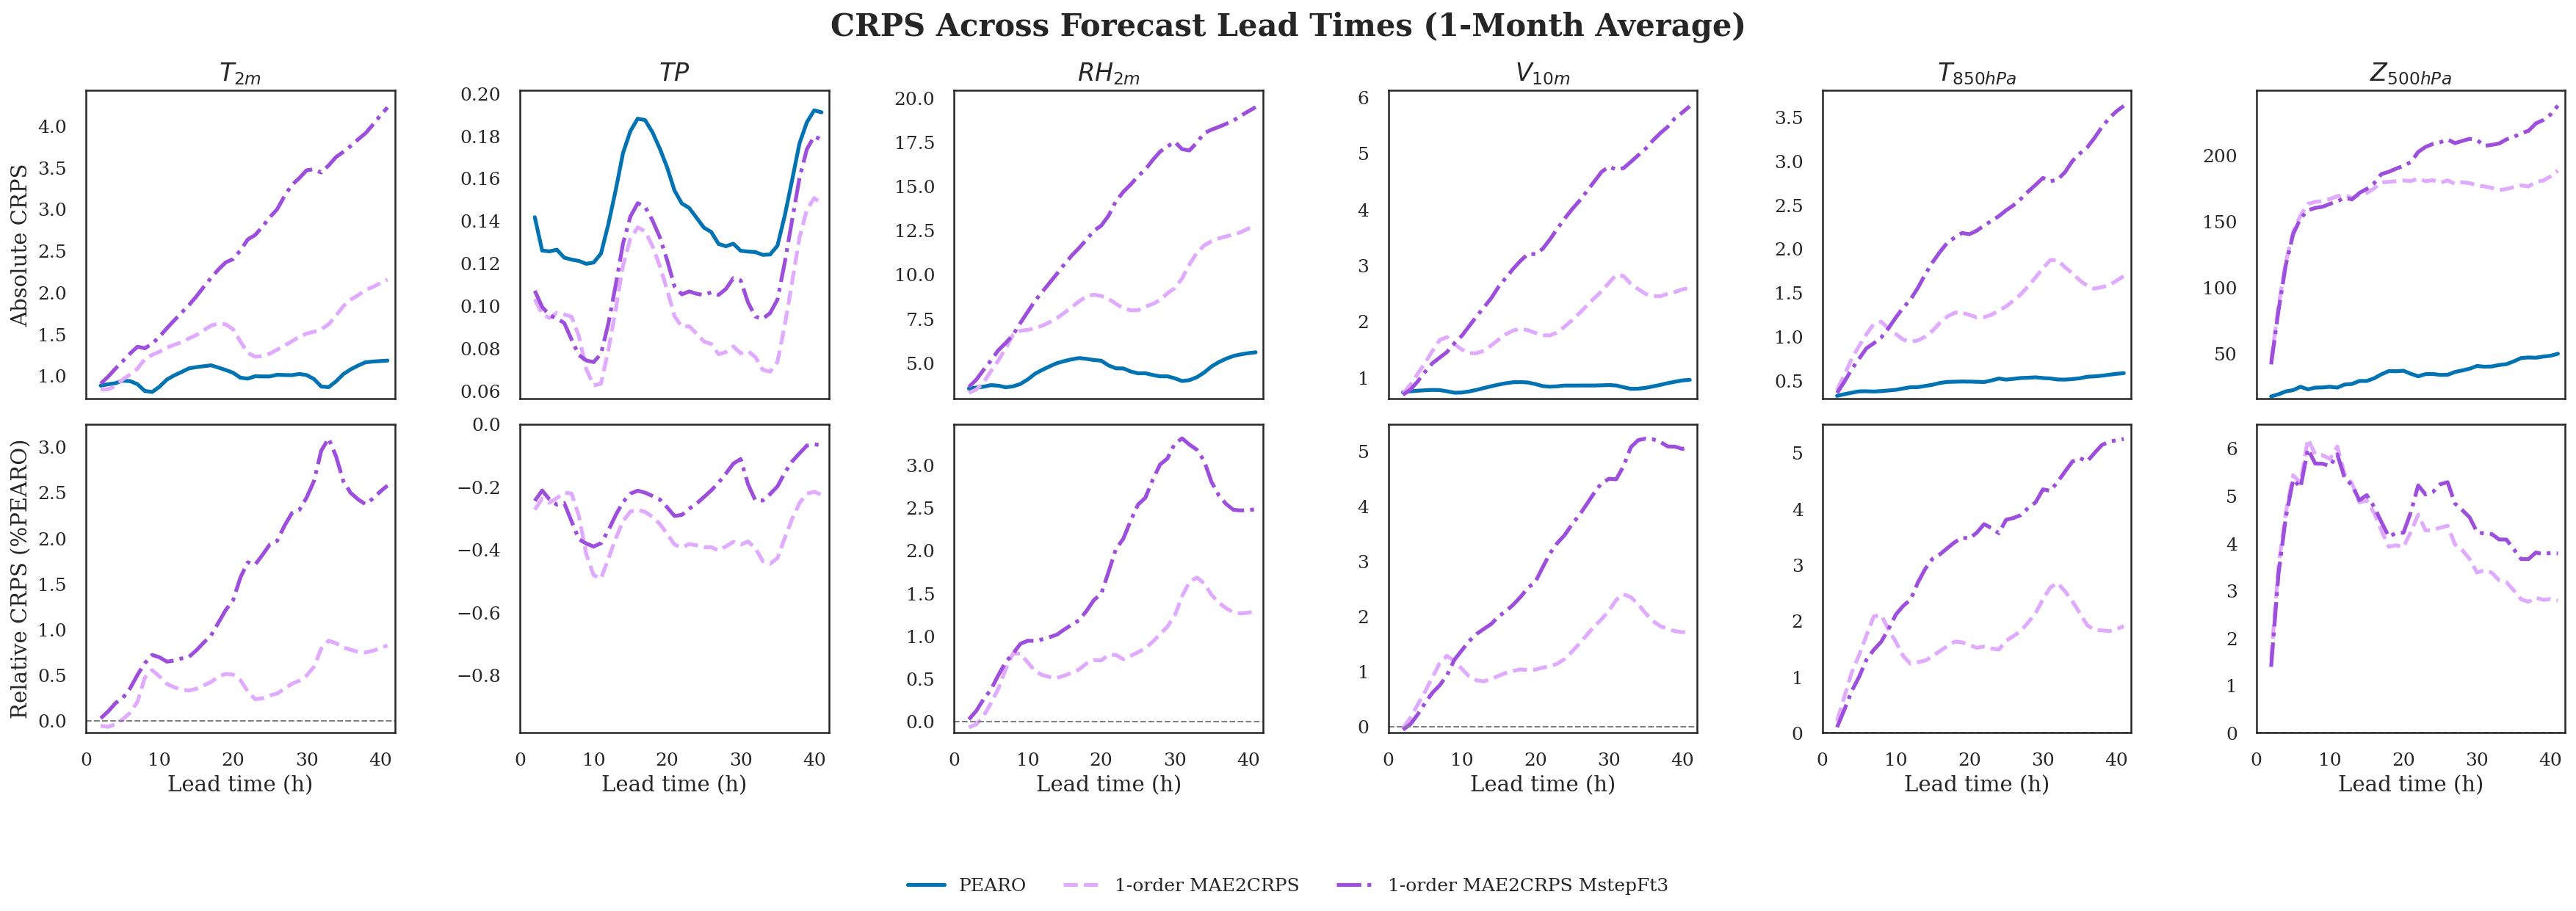

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ---------------------------
# Global aesthetic settings
# ---------------------------
sns.set_theme(style="white", context="talk", font_scale=1.2)
plt.rcParams.update({
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.2,
    "savefig.dpi": 300,
    "figure.dpi": 150,
})

# ---------------------------
# Variables and names
# ---------------------------
vars = ["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m",
        "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]

var_name = [
    r"$T_{2m}$", 
    r"$TP$", 
    r"$RH_{2m}$",
    r"$V_{10m}$", 
    r"$T_{850hPa}$", 
    r"$Z_{500hPa}$"
]

palette = sns.color_palette("colorblind")
linestyles = ['-', '--', '-.', ':', (0, (5, 1)), (0, (3, 1, 1, 1, 1, 1))]

lead_times = np.arange(2, 42)

# ---------------------------
# Create figure: 2 rows x 6 cols
# ---------------------------
fig, axes = plt.subplots(2, 6, figsize=(24, 8), sharex=True)
handles, labels = None, None

# ---------------------------
# Plot loop
# ---------------------------
for i, var in enumerate(vars):
    # Top row: absolute CRPS
    ax_abs = axes[0, i]
    
    # Load data
    poesy = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/pearo_crps_plot_per_param_{var}.npy")
    mae2crps_1order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/preds_crps_plot_per_param_{var}.npy")
    mae2crps_1order_MstepFt3 = np.load(f"/scratch/audrena/py4cast_expe/test_repoAI4SIM/mae2crps_1order_2Mb_4BS_5em4_MstepFt3/june2023_test_poesy/preds_crps_plot_per_param_{var}.npy")

    
    lines_abs = [
        (poesy, "PEARO", palette[0], linestyles[0]),
        (mae2crps_1order, "1-order MAE2CRPS", "#e0aaff", linestyles[1]), 
        (mae2crps_1order_MstepFt3, "1-order MAE2CRPS MstepFt3", "#9d4edd", linestyles[2]),
    ]
    
    for data, label, color, style in lines_abs:
        sns.lineplot(x=lead_times[:len(data)], y=data, label=label, color=color, linestyle=style, linewidth=2.5, ax=ax_abs)
    
    ax_abs.set_title(var_name[i], weight="bold")
    ax_abs.set_xlabel("Lead time (h)")
    ax_abs.set_ylabel("Absolute CRPS")
    ax_abs.grid(False)
    ax_abs.set_xlim(0, 42)
    ymin = min([np.min(d) for d, *_ in lines_abs]) * 0.9
    ymax = max([np.max(d) for d, *_ in lines_abs]) * 1.05
    ax_abs.set_ylim(ymin, ymax)
    
    # Capture legend from the top row
    if handles is None and var == "pearo_t_850hpa":
        handles, labels = ax_abs.get_legend_handles_labels()
    ax_abs.get_legend().remove()
    
    # Bottom row: relative CRPS
    ax_rel = axes[1, i]
    
    # Convert to relative (% of baseline poesy)
    mae2crps_1order_rel = (mae2crps_1order - poesy) / poesy 
    mae2crps_1order_MstepFt3_rel = (mae2crps_1order_MstepFt3 - poesy) / poesy
    
    lines_rel = [
        (mae2crps_1order_rel, "1-order MAE2CRPS", "#e0aaff", linestyles[1]),
        (mae2crps_1order_MstepFt3_rel, "1-order MAE2CRPS MstepFt3", "#9d4edd", linestyles[2]),
    ]
    
    # if var == "pearo_t_850hpa":
    #     mse_PEARP_spectralDS_rel =  (mse_PEARP_spectralDS - poesy[:len(mse_PEARP_spectralDS)]) / poesy[:len(mse_PEARP_spectralDS)]
    #     lines_rel.append((mse_PEARP_spectralDS_rel, "PEARP Spectral Downscale", "#f15bb5", linestyles[4]))
    
    for data, label, color, style in lines_rel:
        sns.lineplot(x=lead_times[:len(data)], y=data, label=label, color=color, linestyle=style, linewidth=2.5, ax=ax_rel)
    
    ax_rel.set_title(var_name[i], weight="bold")
    ax_rel.set_xlabel("Lead time (h)")
    ax_rel.set_ylabel("Relative CRPS (%PEARO)")
    ax_rel.grid(False)
    ax_rel.set_xlim(0, 42)
    ymin = min(min([np.min(d) for d, *_ in lines_rel]), 0) * 2
    ymax = max(max([np.max(d) for d, *_ in lines_rel]), 0) * 1.05
    ax_rel.set_ylim(ymin, ymax)
    ax_rel.get_legend().remove()
    # Optional: add horizontal line at 100% in relative plots
    ax_rel.axhline(0, color="gray", linestyle="--", linewidth=1)


for ax_row in axes:
    for ax in ax_row:
        ax.set_aspect(aspect='auto')  # 'equal' can be too extreme for line plots
        ax.set_box_aspect(1)

# Keep only y-labels on the first column
for row in axes:
    for j, ax in enumerate(row):
        if j != 0:
            ax.set_ylabel("")
# Keep titles only on first (top) row
for j in range(6):
    axes[1, j].set_title("")  # remove title from second row


# ---------------------------
# Global layout and legend
# ---------------------------
fig.suptitle("CRPS Across Forecast Lead Times (1-Month Average)", fontsize=20, weight="bold", y=1.02)
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, fontsize=12)
plt.tight_layout()
plt.subplots_adjust(bottom=0.2, top=0.93)

# ---------------------------
# Save figure
# ---------------------------
plt.savefig("CRPS_absolute_relative_comparison.png", bbox_inches="tight", dpi=300)
plt.show()


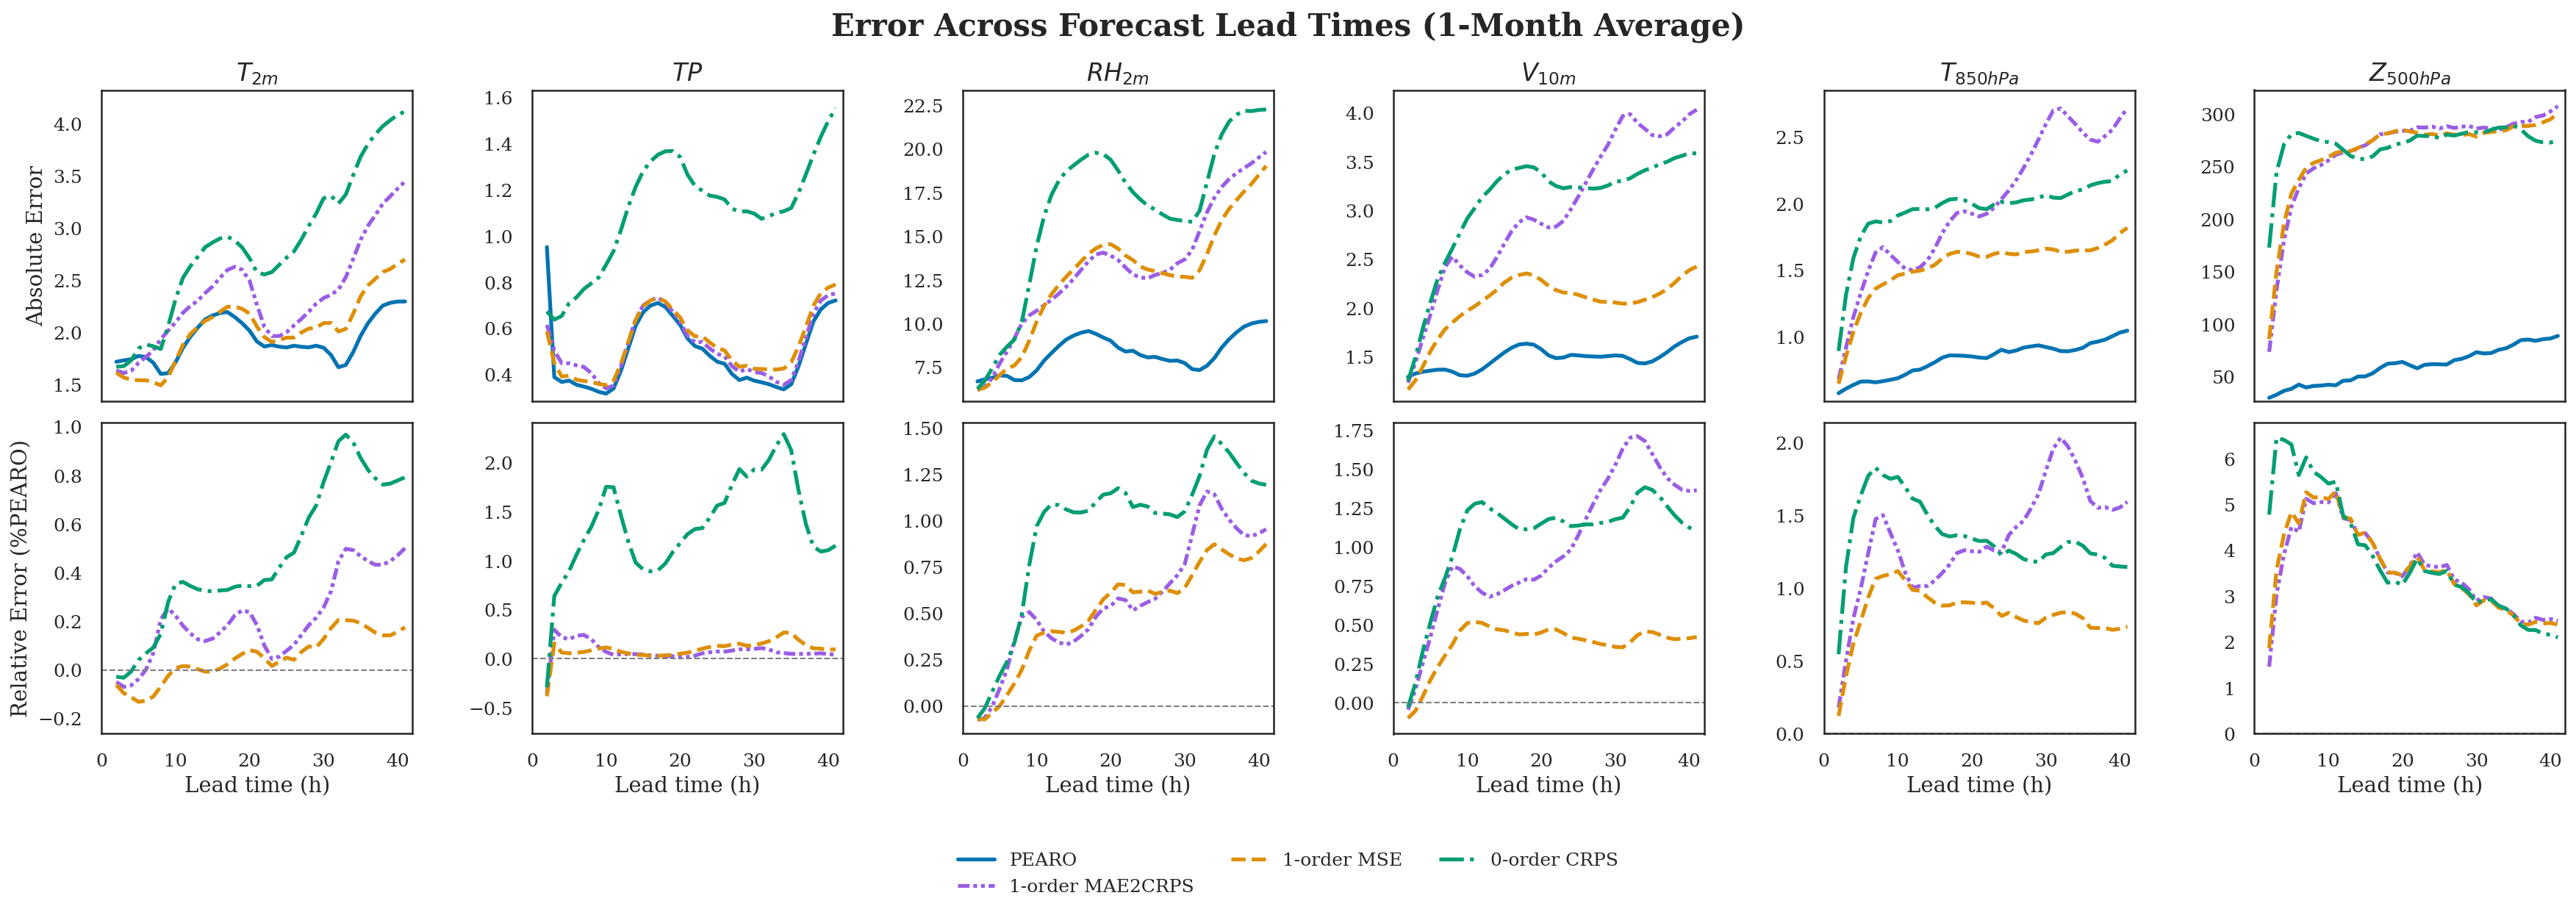

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ---------------------------
# Global aesthetic settings
# ---------------------------
sns.set_theme(style="white", context="talk", font_scale=1.2)
plt.rcParams.update({
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.2,
    "savefig.dpi": 300,
    "figure.dpi": 150,
})

# ---------------------------
# Variables and names
# ---------------------------
vars = ["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m",
        "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]

var_name = [
    r"$T_{2m}$", 
    r"$TP$", 
    r"$RH_{2m}$",
    r"$V_{10m}$", 
    r"$T_{850hPa}$", 
    r"$Z_{500hPa}$"
]

palette = sns.color_palette("colorblind")
linestyles = ['-', '--', '-.', ':', (0, (5, 1)), (0, (3, 1, 1, 1, 1, 1))]

lead_times = np.arange(2, 42)

# ---------------------------
# Create figure: 2 rows x 6 cols
# ---------------------------
fig, axes = plt.subplots(2, 6, figsize=(24, 8), sharex=True)
handles, labels = None, None

# ---------------------------
# Plot loop
# ---------------------------
for i, var in enumerate(vars):
    # Top row: absolute CRPS
    ax_abs = axes[0, i]
    
    # Load data
    poesy = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/pearo_error_plot_per_param_{var}.npy")
    mse_1order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/base_1order_5em4/june2023_test_poesy/preds_error_plot_per_param_{var}.npy")
    crps_0order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/crps_0order_5em4_2M_2BS/june2023_test_poesy/preds_error_plot_per_param_{var}.npy")
    # mae2crps_0order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_0order_5em4_2M_2BS/june2023_test_poesy/preds_error_plot_per_param_{var}.npy")
    mae2crps_1order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/preds_error_plot_per_param_{var}.npy")

    
    lines_abs = [
        (poesy, "PEARO", palette[0], linestyles[0]),
        (mae2crps_1order, "1-order MAE2CRPS", "#9b5de5", linestyles[5]),
        # (mae2crps_0order, "0-order MAE2CRPS", "#9a031e", linestyles[3])
        (mse_1order, "1-order MSE", palette[1], linestyles[1]),
        (crps_0order, "0-order CRPS", palette[2], linestyles[2]),    
    ]
    
    # if var == "pearo_t_850hpa":
    #     mse_PEARP_spectralDS = np.load(
    #         f"/scratch/audrena/py4cast_expe/titan_21var/mse_ARPdownscale_5em4_multiscale/test_poesy/preds_error_plot_per_param_{var}.npy"
    #     )[1:]
    #     lines_abs.append((mse_PEARP_spectralDS, "PEARP Spectral Downscale", "#f15bb5", linestyles[4]))
    
    for data, label, color, style in lines_abs:
        sns.lineplot(x=lead_times[:len(data)], y=data, label=label, color=color, linestyle=style, linewidth=2.5, ax=ax_abs)
    
    ax_abs.set_title(var_name[i], weight="bold")
    ax_abs.set_xlabel("Lead time (h)")
    ax_abs.set_ylabel("Absolute Error")
    ax_abs.grid(False)
    ax_abs.set_xlim(0, 42)
    ymin = min([np.min(d) for d, *_ in lines_abs]) * 0.9
    ymax = max([np.max(d) for d, *_ in lines_abs]) * 1.05
    ax_abs.set_ylim(ymin, ymax)
    
    # Capture legend from the top row
    if handles is None and var == "pearo_t_850hpa":
        handles, labels = ax_abs.get_legend_handles_labels()
    ax_abs.get_legend().remove()
    
    # Bottom row: relative CRPS
    ax_rel = axes[1, i]
    
    # Convert to relative (% of baseline poesy)
    mae2crps_1order_rel = (mae2crps_1order - poesy) / poesy 
    mse_1order_rel = (mse_1order - poesy) / poesy 
    crps_0order_rel = (crps_0order - poesy) / poesy 
    # mae2crps_0order_rel = (mae2crps_0order - poesy) / poesy 
    
    
    lines_rel = [
        (mae2crps_1order_rel, "1-order MAE2CRPS", "#9b5de5", linestyles[5]),
        # (mae2crps_0order_rel, "0-order MAE2CRPS", "#9a031e", linestyles[3])]
        (mse_1order_rel, "1-order MSE", palette[1], linestyles[1]),
        (crps_0order_rel, "0-order CRPS", palette[2], linestyles[2]),
    ]
    
    # if var == "pearo_t_850hpa":
    #     mse_PEARP_spectralDS_rel =  (mse_PEARP_spectralDS - poesy[:len(mse_PEARP_spectralDS)]) / poesy[:len(mse_PEARP_spectralDS)]
    #     lines_rel.append((mse_PEARP_spectralDS_rel, "PEARP Spectral Downscale", "#f15bb5", linestyles[4]))
    
    for data, label, color, style in lines_rel:
        sns.lineplot(x=lead_times[:len(data)], y=data, label=label, color=color, linestyle=style, linewidth=2.5, ax=ax_rel)
    
    ax_rel.set_title(var_name[i], weight="bold")
    ax_rel.set_xlabel("Lead time (h)")
    ax_rel.set_ylabel("Relative Error (%PEARO)")
    ax_rel.grid(False)
    ax_rel.set_xlim(0, 42)
    ymin = min(min([np.min(d) for d, *_ in lines_rel]), 0) * 2
    ymax = max(max([np.max(d) for d, *_ in lines_rel]), 0) * 1.05
    ax_rel.set_ylim(ymin, ymax)
    ax_rel.get_legend().remove()
    # Optional: add horizontal line at 100% in relative plots
    ax_rel.axhline(0, color="gray", linestyle="--", linewidth=1)


for ax_row in axes:
    for ax in ax_row:
        ax.set_aspect(aspect='auto')  # 'equal' can be too extreme for line plots
        ax.set_box_aspect(1)

# Keep only y-labels on the first column
for row in axes:
    for j, ax in enumerate(row):
        if j != 0:
            ax.set_ylabel("")
# Keep titles only on first (top) row
for j in range(6):
    axes[1, j].set_title("")  # remove title from second row



# ---------------------------
# Global layout and legend
# ---------------------------
fig.suptitle("Error Across Forecast Lead Times (1-Month Average)", fontsize=20, weight="bold", y=1.02)
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, fontsize=12)
plt.tight_layout()
plt.subplots_adjust(bottom=0.2, top=0.93)

# ---------------------------
# Save figure
# ---------------------------
plt.savefig("Error_absolute_relative_comparison.png", bbox_inches="tight", dpi=300)
plt.show()


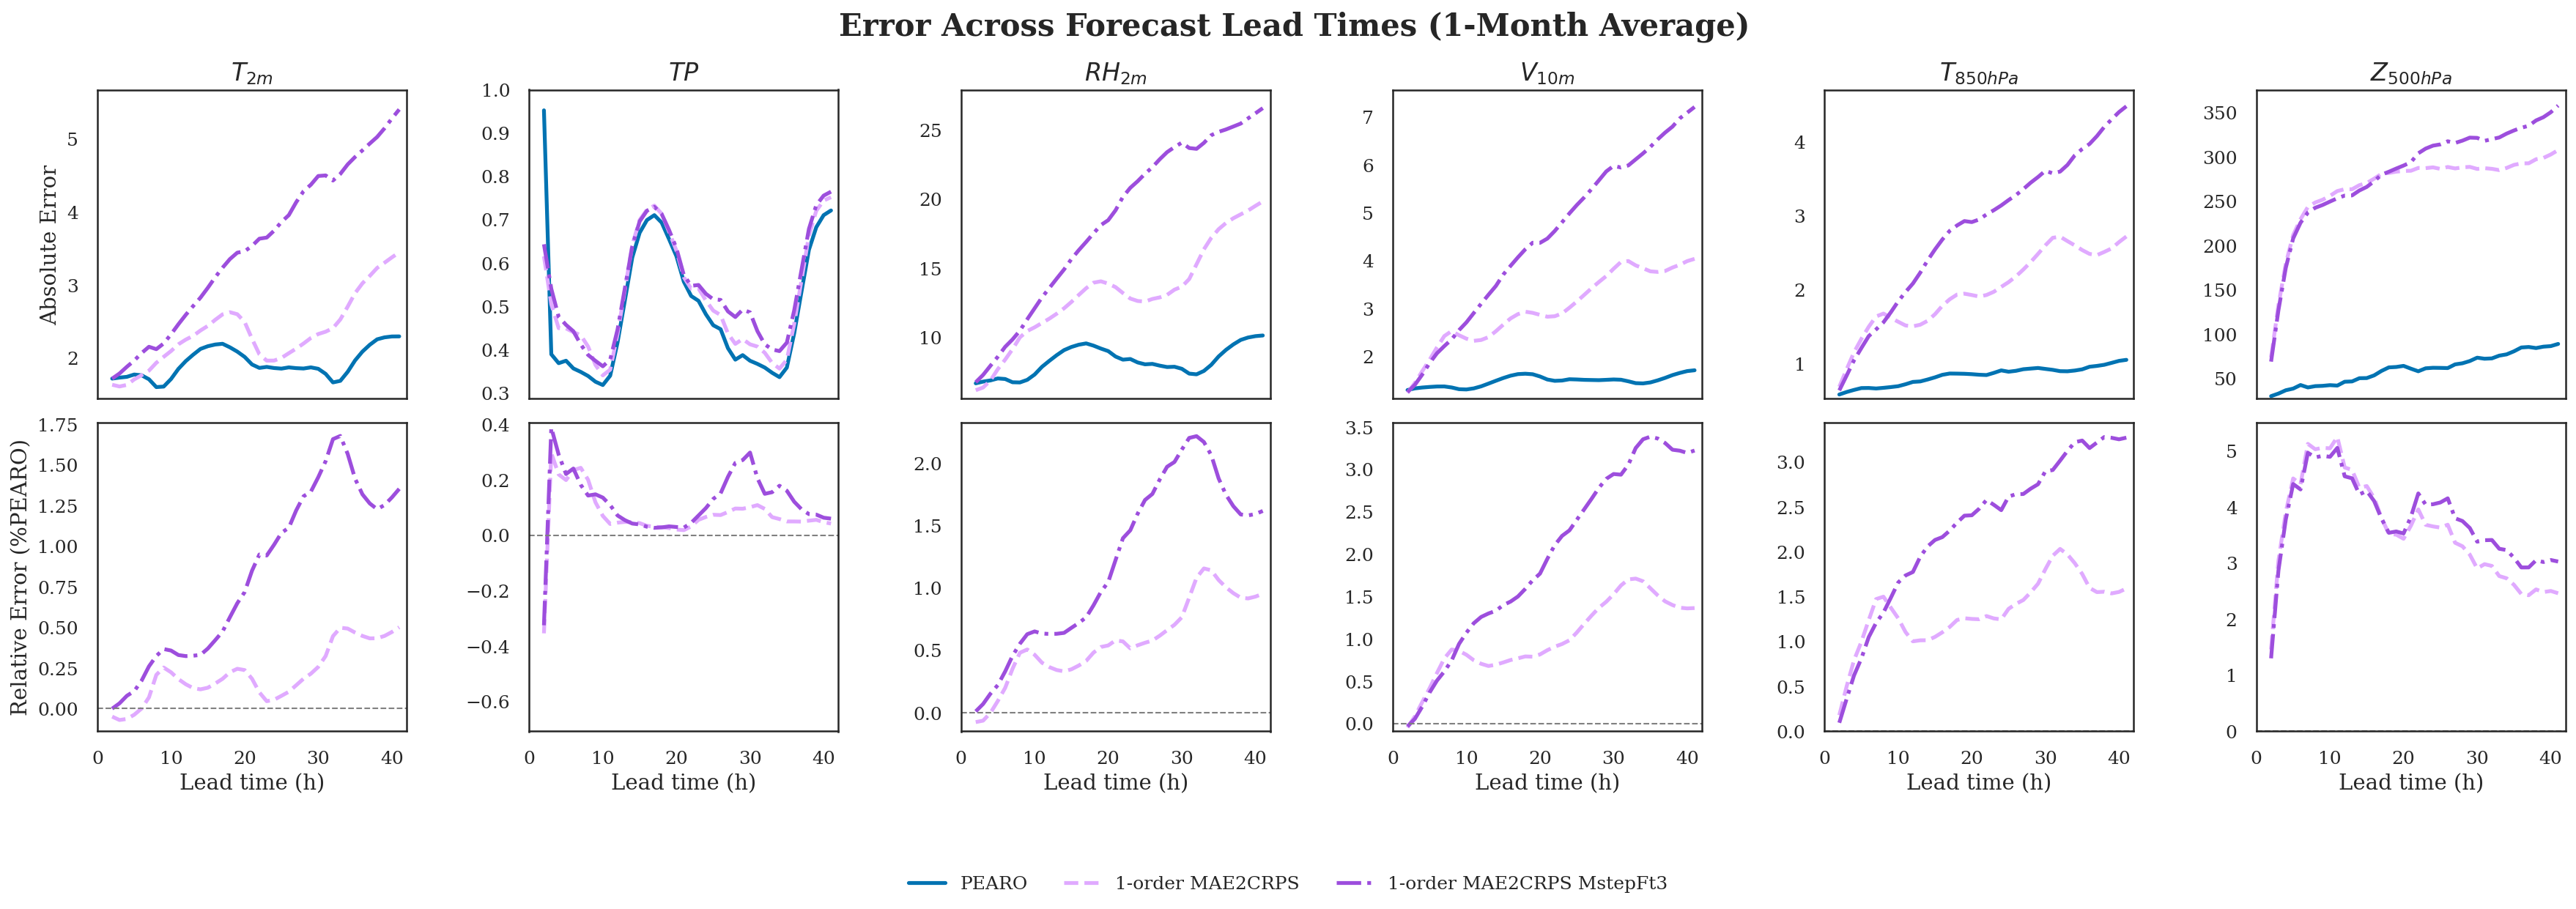

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ---------------------------
# Global aesthetic settings
# ---------------------------
sns.set_theme(style="white", context="talk", font_scale=1.2)
plt.rcParams.update({
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.2,
    "savefig.dpi": 300,
    "figure.dpi": 150,
})

# ---------------------------
# Variables and names
# ---------------------------
vars = ["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m",
        "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]

var_name = [
    r"$T_{2m}$", 
    r"$TP$", 
    r"$RH_{2m}$",
    r"$V_{10m}$", 
    r"$T_{850hPa}$", 
    r"$Z_{500hPa}$"
]

palette = sns.color_palette("colorblind")
linestyles = ['-', '--', '-.', ':', (0, (5, 1)), (0, (3, 1, 1, 1, 1, 1))]

lead_times = np.arange(2, 42)

# ---------------------------
# Create figure: 2 rows x 6 cols
# ---------------------------
fig, axes = plt.subplots(2, 6, figsize=(24, 8), sharex=True)
handles, labels = None, None

# ---------------------------
# Plot loop
# ---------------------------
for i, var in enumerate(vars):
    # Top row: absolute CRPS
    ax_abs = axes[0, i]
    
    # Load data
    poesy = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/pearo_error_plot_per_param_{var}.npy")
    mae2crps_1order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/preds_error_plot_per_param_{var}.npy")
    mae2crps_1order_MstepFt3 = np.load(f"/scratch/audrena/py4cast_expe/test_repoAI4SIM/mae2crps_1order_2Mb_4BS_5em4_MstepFt3/june2023_test_poesy/preds_error_plot_per_param_{var}.npy")

    
    lines_abs = [
        (poesy, "PEARO", palette[0], linestyles[0]),
        (mae2crps_1order, "1-order MAE2CRPS", "#e0aaff", linestyles[1]),
        (mae2crps_1order_MstepFt3, "1-order MAE2CRPS MstepFt3", "#9d4edd", linestyles[2]),  
    ]
    
    for data, label, color, style in lines_abs:
        sns.lineplot(x=lead_times[:len(data)], y=data, label=label, color=color, linestyle=style, linewidth=2.5, ax=ax_abs)
    
    ax_abs.set_title(var_name[i], weight="bold")
    ax_abs.set_xlabel("Lead time (h)")
    ax_abs.set_ylabel("Absolute Error")
    ax_abs.grid(False)
    ax_abs.set_xlim(0, 42)
    ymin = min([np.min(d) for d, *_ in lines_abs]) * 0.9
    ymax = max([np.max(d) for d, *_ in lines_abs]) * 1.05
    ax_abs.set_ylim(ymin, ymax)
    
    # Capture legend from the top row
    if handles is None and var == "pearo_t_850hpa":
        handles, labels = ax_abs.get_legend_handles_labels()
    ax_abs.get_legend().remove()
    
    # Bottom row: relative CRPS
    ax_rel = axes[1, i]
    
    # Convert to relative (% of baseline poesy)
    mae2crps_1order_rel = (mae2crps_1order - poesy) / poesy 
    mae2crps_1order_MstepFt3_rel = (mae2crps_1order_MstepFt3 - poesy) / poesy
    
    lines_rel = [
        (mae2crps_1order_rel, "1-order MAE2CRPS", "#e0aaff", linestyles[1]),
        (mae2crps_1order_MstepFt3_rel, "1-order MAE2CRPS MstepFt3", "#9d4edd", linestyles[2]),
    ]
    
    for data, label, color, style in lines_rel:
        sns.lineplot(x=lead_times[:len(data)], y=data, label=label, color=color, linestyle=style, linewidth=2.5, ax=ax_rel)
    
    ax_rel.set_title(var_name[i], weight="bold")
    ax_rel.set_xlabel("Lead time (h)")
    ax_rel.set_ylabel("Relative Error (%PEARO)")
    ax_rel.grid(False)
    ax_rel.set_xlim(0, 42)
    ymin = min(min([np.min(d) for d, *_ in lines_rel]), 0) * 2
    ymax = max(max([np.max(d) for d, *_ in lines_rel]), 0) * 1.05
    ax_rel.set_ylim(ymin, ymax)
    ax_rel.get_legend().remove()
    # Optional: add horizontal line at 100% in relative plots
    ax_rel.axhline(0, color="gray", linestyle="--", linewidth=1)


for ax_row in axes:
    for ax in ax_row:
        ax.set_aspect(aspect='auto')  # 'equal' can be too extreme for line plots
        ax.set_box_aspect(1)

# Keep only y-labels on the first column
for row in axes:
    for j, ax in enumerate(row):
        if j != 0:
            ax.set_ylabel("")
# Keep titles only on first (top) row
for j in range(6):
    axes[1, j].set_title("")  # remove title from second row



# ---------------------------
# Global layout and legend
# ---------------------------
fig.suptitle("Error Across Forecast Lead Times (1-Month Average)", fontsize=20, weight="bold", y=1.02)
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, fontsize=12)
plt.tight_layout()
plt.subplots_adjust(bottom=0.2, top=0.93)

# ---------------------------
# Save figure
# ---------------------------
plt.savefig("Error_absolute_relative_comparison.png", bbox_inches="tight", dpi=300)
plt.show()


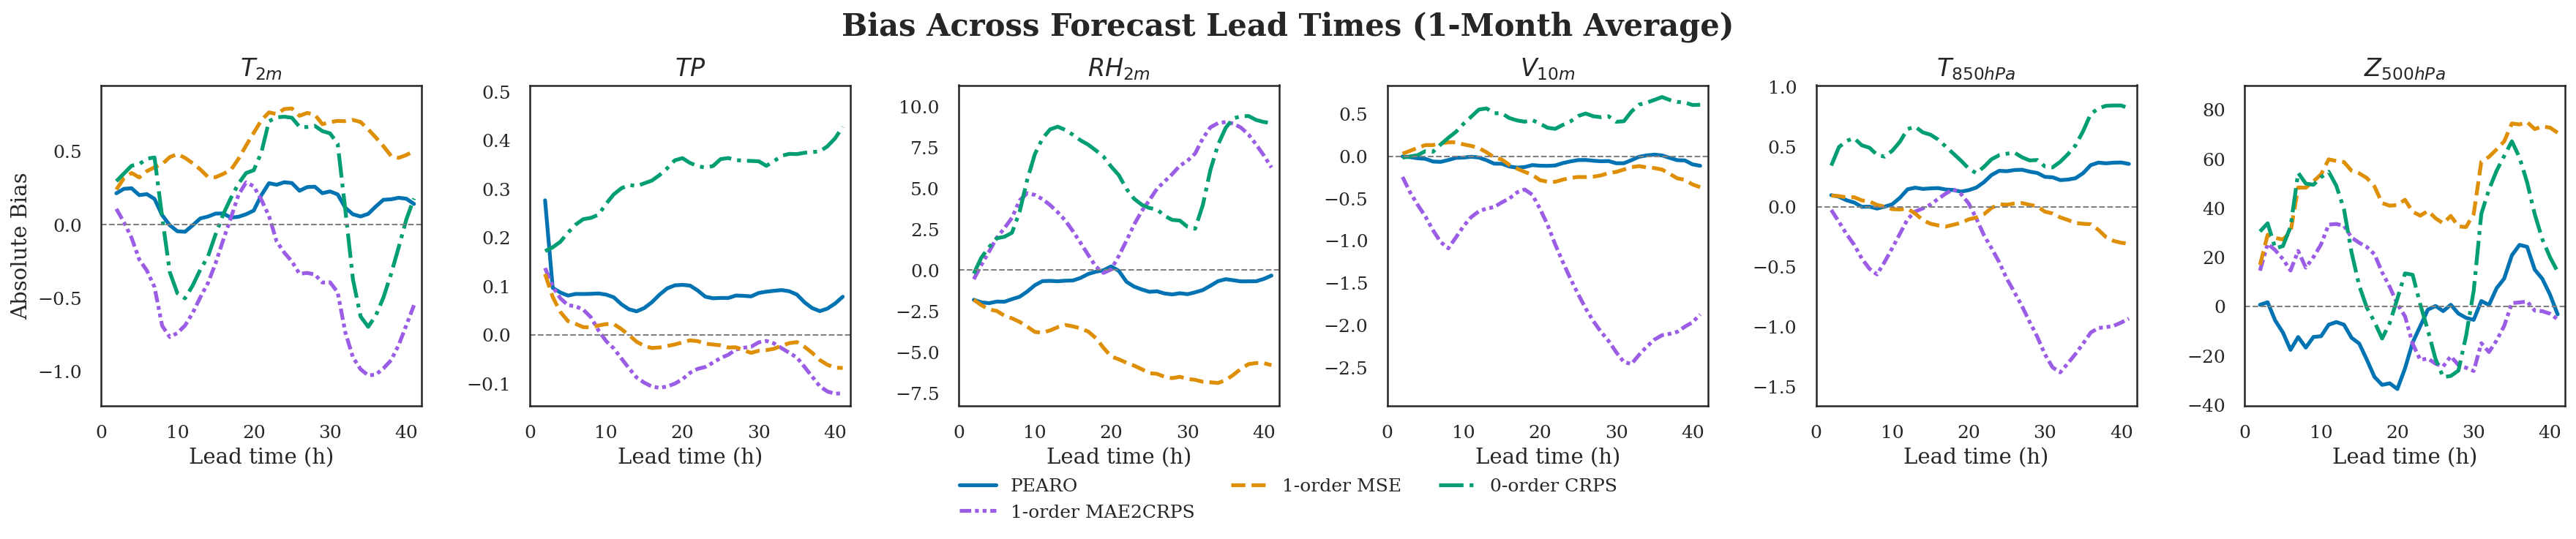

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ---------------------------
# Global aesthetic settings
# ---------------------------
sns.set_theme(style="white", context="talk", font_scale=1.2)
plt.rcParams.update({
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.2,
    "savefig.dpi": 300,
    "figure.dpi": 150,
})

# ---------------------------
# Variables and names
# ---------------------------
vars = ["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m",
        "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]

var_name = [
    r"$T_{2m}$", 
    r"$TP$", 
    r"$RH_{2m}$",
    r"$V_{10m}$", 
    r"$T_{850hPa}$", 
    r"$Z_{500hPa}$"
]

palette = sns.color_palette("colorblind")
linestyles = ['-', '--', '-.', ':', (0, (5, 1)), (0, (3, 1, 1, 1, 1, 1))]

lead_times = np.arange(2, 42)

# ---------------------------
# Create figure: 1 row x 6 cols
# ---------------------------
fig, axes = plt.subplots(1, 6, figsize=(24, 4), sharex=True)
handles, labels = None, None

# ---------------------------
# Plot loop
# ---------------------------
for i, var in enumerate(vars):

    ax = axes[i]

    # Load data
    poesy = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/pearo_bias_plot_per_param_{var}.npy")
    mse_1order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/base_1order_5em4/june2023_test_poesy/preds_bias_plot_per_param_{var}.npy")
    crps_0order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/crps_0order_5em4_2M_2BS/june2023_test_poesy/preds_bias_plot_per_param_{var}.npy")
    # mae2crps_0order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_0order_5em4_2M_2BS/june2023_test_poesy/preds_bias_plot_per_param_{var}.npy")
    mae2crps_1order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/preds_bias_plot_per_param_{var}.npy")

    lines_abs = [
        (poesy, "PEARO", palette[0], linestyles[0]),
        (mae2crps_1order, "1-order MAE2CRPS", "#9b5de5", linestyles[5]),
        # (mae2crps_0order, "0-order MAE2CRPS", "#9a031e", linestyles[3])
        (mse_1order, "1-order MSE", palette[1], linestyles[1]),
        (crps_0order, "0-order CRPS", palette[2], linestyles[2]),  
    ]
    
    # if var == "pearo_t_850hpa":
    #     mse_PEARP_spectralDS = np.load(
    #         f"/scratch/audrena/py4cast_expe/titan_21var/mse_ARPdownscale_5em4_multiscale/test_poesy/preds_bias_plot_per_param_{var}.npy"
    #     )[1:]
    #     lines_abs.append((mse_PEARP_spectralDS, "PEARP Spectral Downscale", "#f15bb5", linestyles[4]))

    # Plot curves
    for data, label, color, style in lines_abs:
        sns.lineplot(
            x=lead_times[:len(data)], y=data,
            label=label, color=color, linestyle=style, linewidth=2.5, ax=ax
        )

    # Formatting
    ax.set_title(var_name[i], weight="bold")
    ax.set_xlabel("Lead time (h)")
    if i == 0:
        ax.set_ylabel("Absolute Bias")
    else:
        ax.set_ylabel("")

    ax.grid(False)
    ax.set_xlim(0, 42)
    
    ymax = max(max([np.max(d) for d, *_ in lines_abs]),0) *1.2
    ymin = min(min([np.min(d) for d, *_ in lines_abs]),0) *1.2
    
    ax.set_ylim(ymin, ymax)
    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    # Capture legend once
    if handles is None and var == "pearo_t2m_2m":
        handles, labels = ax.get_legend_handles_labels()

    ax.get_legend().remove()
    ax.set_aspect(aspect='auto')
    ax.set_box_aspect(1)

# ---------------------------
# Global layout and legend
# ---------------------------
fig.suptitle("Bias Across Forecast Lead Times (1-Month Average)", fontsize=20, weight="bold", y=1.1)
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, fontsize=12, bbox_to_anchor=(0.5, -0.1))

plt.tight_layout()
plt.subplots_adjust(bottom=0.2, top=0.93)

# ---------------------------
# Save figure
# ---------------------------
plt.savefig("Bias_absolute_comparison.png", bbox_inches="tight", dpi=300)
plt.show()


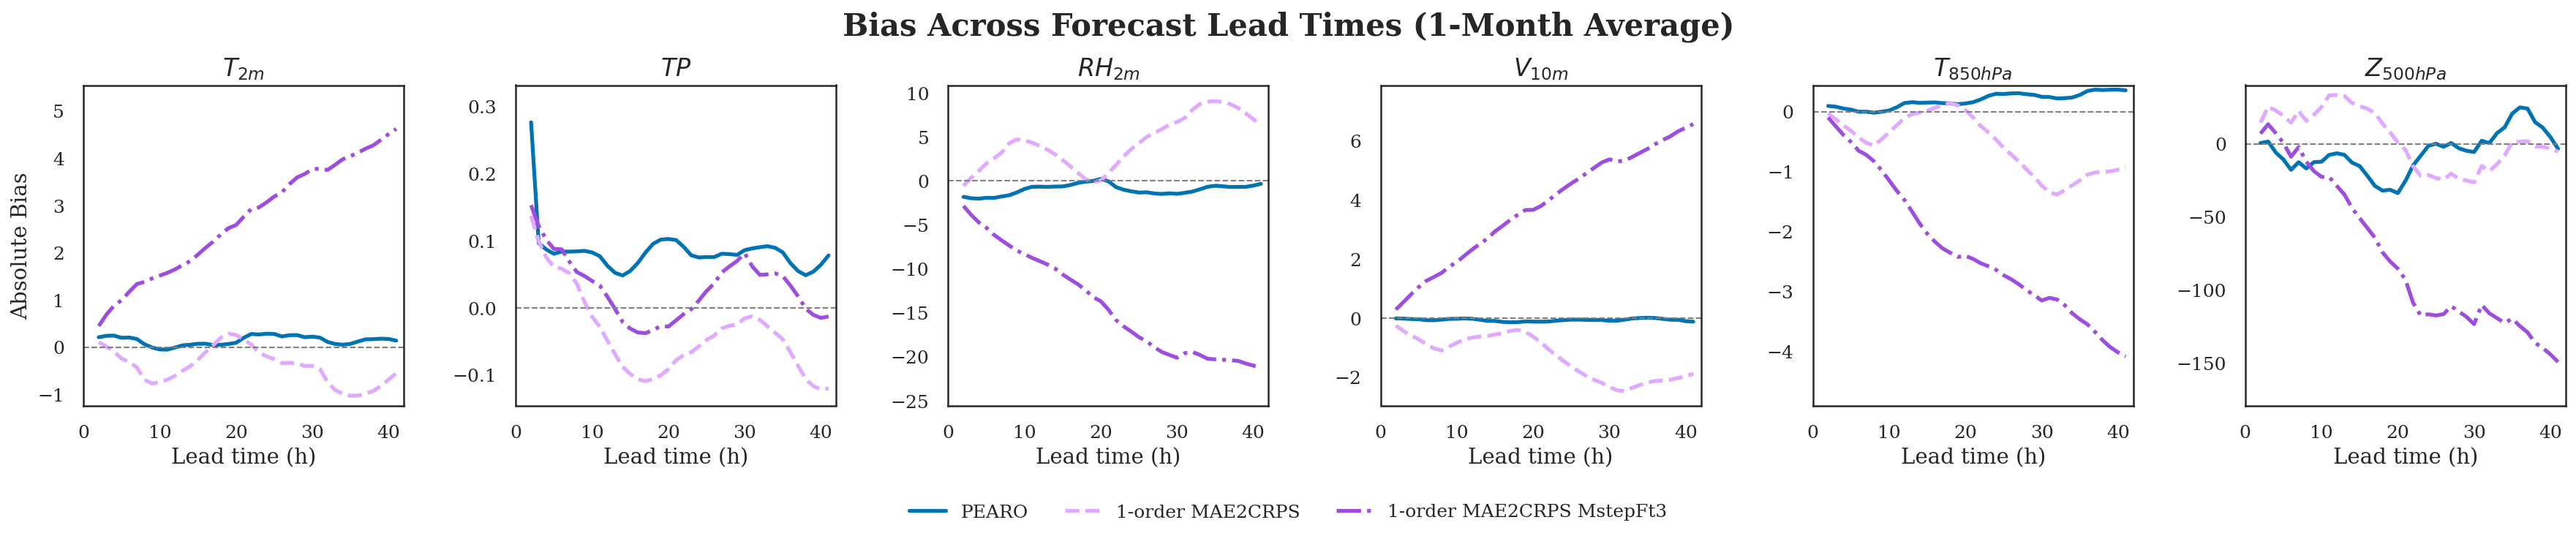

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ---------------------------
# Global aesthetic settings
# ---------------------------
sns.set_theme(style="white", context="talk", font_scale=1.2)
plt.rcParams.update({
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.2,
    "savefig.dpi": 300,
    "figure.dpi": 150,
})

# ---------------------------
# Variables and names
# ---------------------------
vars = ["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m",
        "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]

var_name = [
    r"$T_{2m}$", 
    r"$TP$", 
    r"$RH_{2m}$",
    r"$V_{10m}$", 
    r"$T_{850hPa}$", 
    r"$Z_{500hPa}$"
]

palette = sns.color_palette("colorblind")
linestyles = ['-', '--', '-.', ':', (0, (5, 1)), (0, (3, 1, 1, 1, 1, 1))]

lead_times = np.arange(2, 42)

# ---------------------------
# Create figure: 1 row x 6 cols
# ---------------------------
fig, axes = plt.subplots(1, 6, figsize=(24, 4), sharex=True)
handles, labels = None, None

# ---------------------------
# Plot loop
# ---------------------------
for i, var in enumerate(vars):

    ax = axes[i]

    # Load data
    poesy = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/pearo_bias_plot_per_param_{var}.npy")
    mae2crps_1order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/preds_bias_plot_per_param_{var}.npy")
    mae2crps_1order_MstepFt3 = np.load(f"/scratch/audrena/py4cast_expe/test_repoAI4SIM/mae2crps_1order_2Mb_4BS_5em4_MstepFt3/june2023_test_poesy/preds_bias_plot_per_param_{var}.npy")

    lines_abs = [
        (poesy, "PEARO", palette[0], linestyles[0]),
        (mae2crps_1order, "1-order MAE2CRPS", "#e0aaff", linestyles[1]),
        (mae2crps_1order_MstepFt3, "1-order MAE2CRPS MstepFt3", "#9d4edd", linestyles[2]),
    ]

    # Plot curves
    for data, label, color, style in lines_abs:
        sns.lineplot(
            x=lead_times[:len(data)], y=data,
            label=label, color=color, linestyle=style, linewidth=2.5, ax=ax
        )

    # Formatting
    ax.set_title(var_name[i], weight="bold")
    ax.set_xlabel("Lead time (h)")
    if i == 0:
        ax.set_ylabel("Absolute Bias")
    else:
        ax.set_ylabel("")

    ax.grid(False)
    ax.set_xlim(0, 42)
    
    ymax = max(max([np.max(d) for d, *_ in lines_abs]),0) *1.2
    ymin = min(min([np.min(d) for d, *_ in lines_abs]),0) *1.2
    
    ax.set_ylim(ymin, ymax)
    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    # Capture legend once
    if handles is None and var == "pearo_t2m_2m":
        handles, labels = ax.get_legend_handles_labels()

    ax.get_legend().remove()
    ax.set_aspect(aspect='auto')
    ax.set_box_aspect(1)

# ---------------------------
# Global layout and legend
# ---------------------------
fig.suptitle("Bias Across Forecast Lead Times (1-Month Average)", fontsize=20, weight="bold", y=1.1)
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, fontsize=12, bbox_to_anchor=(0.5, -0.1))

plt.tight_layout()
plt.subplots_adjust(bottom=0.2, top=0.93)

# ---------------------------
# Save figure
# ---------------------------
plt.savefig("Bias_absolute_comparison.png", bbox_inches="tight", dpi=300)
plt.show()


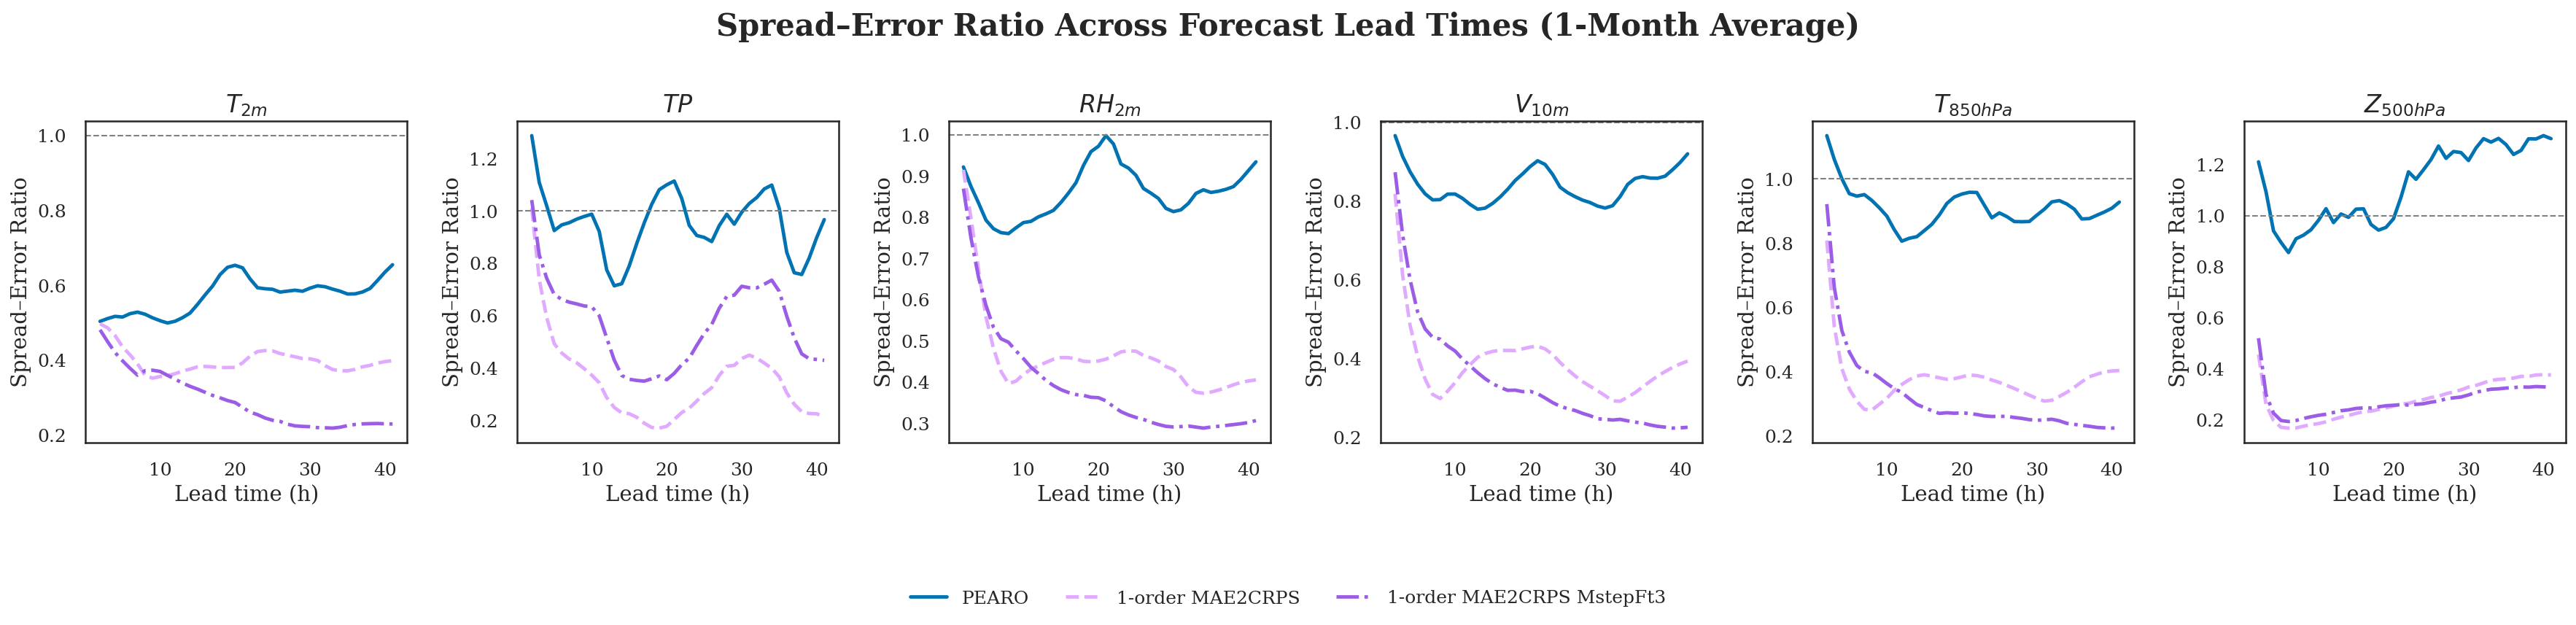

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ---------------------------
# Global aesthetics
# ---------------------------
sns.set_theme(style="white", context="talk", font_scale=1.2)
plt.rcParams.update({
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.2,
    "savefig.dpi": 300,
    "figure.dpi": 150,
})

# ---------------------------
# Variables and names
# ---------------------------
vars = [
    "pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m",
    "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"
]

var_name = [
    r"$T_{2m}$", r"$TP$", r"$RH_{2m}$",
    r"$V_{10m}$", r"$T_{850hPa}$", r"$Z_{500hPa}$"
]

palette = sns.color_palette("colorblind")
linestyles = ['-', '--', '-.', ':', (0, (5, 1)), (0, (3, 1, 1, 1, 1, 1))]
lead_times = np.arange(2, 42)

# ---------------------------
# Paths to each model
# ---------------------------
model_paths = {
    "PEARO": (
        "titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy",
        "pearo"   
    ),
    "1-order MAE2CRPS": (
        "titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy",
        "preds"
    )
    ,
    "1-order MAE2CRPS MstepFt3": (
        "test_repoAI4SIM/mae2crps_1order_2Mb_4BS_5em4_MstepFt3/june2023_test_poesy",
        "preds"
    )
}

# ---------------------------
# Helper: loads correct filename depending on model
# ---------------------------
def load_var(base_path, prefix, var):
    return np.load(
        f"/scratch/audrena/py4cast_expe/{base_path}/{prefix}_spread_error_ratio_plot_per_param_{var}.npy"
    )

# ---------------------------
# Create figure
# ---------------------------
fig, axes = plt.subplots(1, 6, figsize=(24, 8))
legend_handles = legend_labels = None

for i, (var, vname) in enumerate(zip(vars, var_name)):

    ax = axes[i]
    lines = []

    # Load standard models
    for (label, (path, prefix)), color, ls in zip(model_paths.items(), palette, linestyles):
        data = load_var(path, prefix, var)
        if label == "1-order MAE2CRPS":
            color = "#e0aaff"  # custom color
        elif label == "1-order MAE2CRPS MstepFt3":
            color = "#9b5de5"  # custom color
        lines.append((label, data, color, ls))

    # Plot all lines
    for label, data, color, ls in lines:
        sns.lineplot(
            x=lead_times[:len(data)],
            y=data,
            ax=ax,
            label=label,
            color=color,
            linestyle=ls,
            linewidth=2.3
        )

    ax.set_title(vname, weight="bold")
    ax.set_xlabel("Lead time (h)")
    ax.set_ylabel("Spread–Error Ratio")
    ax.axhline(1, color="gray", ls="--", lw=1)
    ax.set_box_aspect(1)      # ← PERFECTLY SQUARE SUBPLOTS

    # Save legend reference once
    if legend_handles is None and var == "pearo_t_850hpa":
        legend_handles, legend_labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()

# ---------------------------
# Global layout
# ---------------------------
fig.suptitle(
    "Spread–Error Ratio Across Forecast Lead Times (1-Month Average)",
    fontsize=20, weight="bold", y=0.9
)

fig.legend(
    legend_handles, legend_labels,
    loc="lower center", ncol=3, frameon=False, fontsize=12, bbox_to_anchor=(0.5, 0.2),
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.30, top=0.88)

plt.savefig("spread_error_ratio.png",
            dpi=300, bbox_inches="tight")
plt.show()


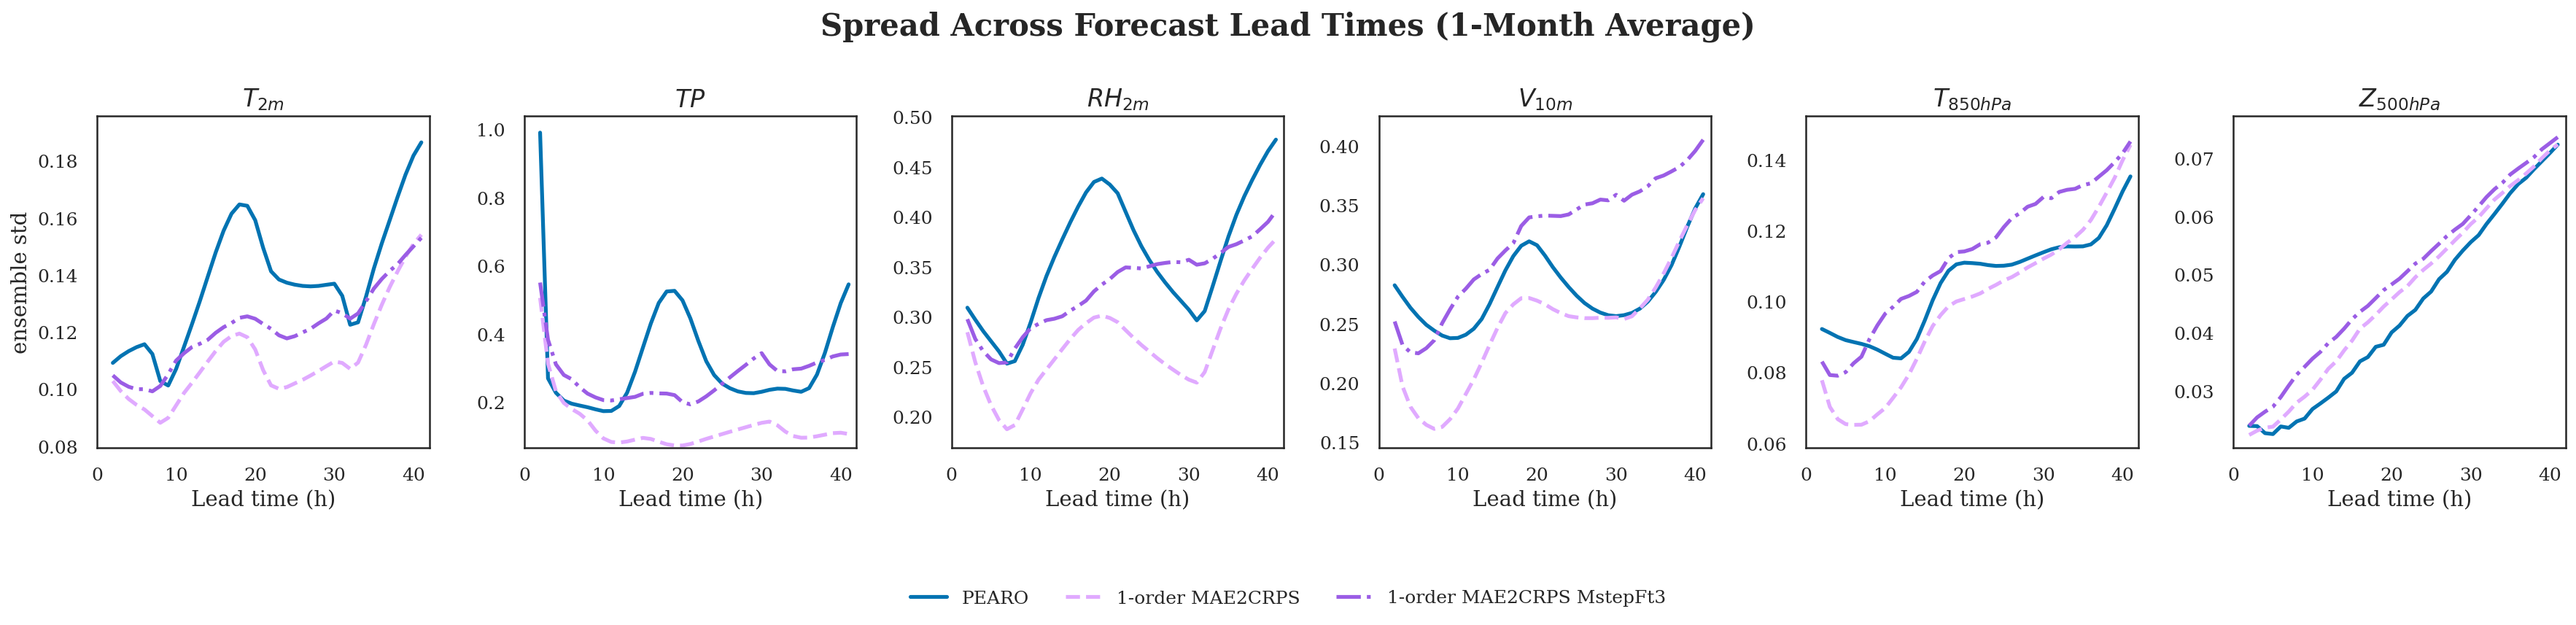

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from tbparse import SummaryReader

# ---------------------------
# Global aesthetic settings
# ---------------------------
sns.set_theme(style="white", context="talk", font_scale=1.2)
plt.rcParams.update({
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.2,
    "savefig.dpi": 300,
    "figure.dpi": 150,
})

# ---------------------------
# Variables and names
# ---------------------------
vars = ["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m",
        "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]

var_name = [
    r"$T_{2m}$",
    r"$TP$",
    r"$RH_{2m}$",
    r"$V_{10m}$",
    r"$T_{850hPa}$",
    r"$Z_{500hPa}$"
]

palette = sns.color_palette("colorblind")
linestyles = ['-', '--', '-.', ':', (0, (5, 1)), (0, (3, 1, 1, 1, 1, 1))]

lead_times = np.arange(2, 42)

# ---------------------------
# Create figure: 1 row × 6 cols (ABSOLUTE ONLY)
# ---------------------------
fig, axes = plt.subplots(1, 6, figsize=(24, 8))
handles, labels = None, None

# ---------------------------
# Plot loop (ABSOLUTE ONLY)
# ---------------------------
for i, var in enumerate(vars):
    ax = axes[i]

    # Load data
    poesy_logdir = f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/Test_std_timestep_{var}_poesy_refacto_EURW1S40_refacto/"
    poesy = SummaryReader(poesy_logdir).scalars['value']
    mae2crps_1order = SummaryReader(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/Test_std_timestep_{var}_preds").scalars['value']
    mae2crps_1order_MstepFt3 = SummaryReader(f"/scratch/audrena/py4cast_expe/test_repoAI4SIM/mae2crps_1order_2Mb_4BS_5em4_MstepFt3/june2023_test_poesy/Test_std_timestep_{var}_preds").scalars['value']

    # Build absolute curve list
    lines_abs = [
        (poesy, "PEARO", palette[0], linestyles[0]),
        (mae2crps_1order, "1-order MAE2CRPS", "#e0aaff", linestyles[1]),
        (mae2crps_1order_MstepFt3, "1-order MAE2CRPS MstepFt3","#9b5de5" , linestyles[2]),
    ]

    # Plot absolute
    for data, label, color, style in lines_abs:
        sns.lineplot(
            x=lead_times[:len(data)], y=data,
            label=label, color=color, linestyle=style,
            linewidth=2.5, ax=ax
        )

    ax.set_title(var_name[i], weight="bold")
    ax.set_xlabel("Lead time (h)")
    if i == 0:
        ax.set_ylabel("ensemble std")
    else:
        ax.set_ylabel("")

    ax.grid(False)
    ax.set_xlim(0, 42)

    ymin = min([np.min(d) for d, *_ in lines_abs]) * 0.9
    ymax = max([np.max(d) for d, *_ in lines_abs]) * 1.05
    ax.set_ylim(ymin, ymax)

    # Capture legend once
    if handles is None and var == "pearo_t_850hpa":
        handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()

    # Square subplots
    ax.set_box_aspect(1)

# ---------------------------
# Global layout and legend
# ---------------------------
fig.suptitle(
    "Spread Across Forecast Lead Times (1-Month Average)",
    fontsize=20, weight="bold", y=0.9
)

fig.legend(handles, labels, loc="lower center", ncol=3,
           frameon=False, fontsize=12, bbox_to_anchor=(0.5, 0.2))

plt.tight_layout()
plt.subplots_adjust(bottom=0.30, top=0.88)

# ---------------------------
# Save figure
# ---------------------------
plt.savefig("spread.png", bbox_inches="tight", dpi=300)
plt.show()
